In [3]:
## Imports
#
# This is the "no emulation" version of the workflow: we do NOT train hmepy
# emulators. Instead we sample the parameter space, run the PyELQ forward model
# directly at every sampled point, and rank the points by how well they match the
# observations. Consequently none of the `hmepy` machinery is imported here.

import os
import importlib
import random
import sys
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/matplotlib-cache")

import numpy as np
import pandas as pd
from scipy.stats import qmc

try:
    from dotenv import load_dotenv
except ImportError:
    load_dotenv = None

mipyelq_src = Path("/Users/hamid/mirico/mipyelq/src")
if mipyelq_src.exists() and str(mipyelq_src) not in sys.path:
    sys.path.insert(0, str(mipyelq_src))

for candidate_dir in (Path.cwd(), Path.cwd() / "mirico"):
    if (candidate_dir / "forward_model.py").exists():
        candidate_path = str(candidate_dir.resolve())
        if candidate_path not in sys.path:
            sys.path.insert(0, candidate_path)
        break

if load_dotenv is not None:
    load_dotenv()

from pyelq.source_map import SourceMap
from pyelq.coordinate_system import LLA
from pyelq.gas_species import CH4
from pyelq.dispersion_model.gaussian_plume import GaussianPlume
from pyelq.dispersion_model.turbulence_model import DraxlerModel
from pyelq.sensor.sensor import SensorGroup
from pyelq.sensor.beam import Beam
from pyelq.meteorology import meteorology
from pyelq.component.background import SpatioTemporalBackground
from pyelq.model import ELQModel
from pyelq.data_access.mirico_data import MiricoData
from pyelq.data_access.xarray import load_from_xarray

# Reload forward_model on every run so edits to forward_model.py are always
# picked up without needing a full kernel restart (Python caches imports).
import forward_model as _forward_model
_forward_model = importlib.reload(_forward_model)
from forward_model import ForwardModel


def _to_sensor_compatible(self, n_beam_knots=500, quality_threshold=10):
    if self.settings is None or self.report is None:
        raise ValueError("Missing settings or report data, cannot construct SensorGroup object.")

    sensor_group = SensorGroup()
    valid_report = self.report[self.report["measurement_validity"] >= quality_threshold]

    for identifier in valid_report["pyelq_retro_id"].unique():
        retro_measurements = valid_report[valid_report["pyelq_retro_id"] == identifier]

        sensor = Beam(label=identifier, n_beam_knots=n_beam_knots)
        sensor.time = pd.to_datetime(retro_measurements["timestamp"]).array
        sensor.concentration = retro_measurements["ch4"] * 1e6
        sensor.std_err = retro_measurements["ch4_stderr"] * 1e6

        orion_lla = self.settings[identifier]["orion_lla"]
        retro_lla = self.settings[identifier]["retro_lla"]
        lat_pair, lng_pair, alt_pair = zip(orion_lla, retro_lla)
        sensor.location = LLA(
            latitude=np.array(lat_pair), longitude=np.array(lng_pair), altitude=np.array(alt_pair)
        )

        sensor_group.add_sensor(sensor)

    return sensor_group

def _insert_low_res_wind_compatible(self, meteorology):
    meteorology.time = pd.to_datetime(self.report["timestamp"]).array
    meteorology.u_component = self.report["windy"].to_numpy()
    meteorology.v_component = self.report["windx"].to_numpy()
    meteorology.w_component = self.report["windz"].to_numpy()

def _insert_high_res_wind_compatible(self, meteorology):
    high_res_time_column = "windtime" if "windtime" in self.high_res_wind.columns else "timestamp"
    meteorology.time = pd.to_datetime(self.high_res_wind[high_res_time_column]).array
    meteorology.u_component = self.high_res_wind["windy"].to_numpy()
    meteorology.v_component = self.high_res_wind["windx"].to_numpy()
    meteorology.w_component = self.high_res_wind["windz"].to_numpy()

    for var in ["temperature", "pressure", "wind_turbulence_horizontal", "wind_turbulence_vertical"]:
        setattr(meteorology, var, self._interpolate_low_res_met(getattr(meteorology, var)))

MiricoData.to_sensor = _to_sensor_compatible
MiricoData._insert_low_res_wind = _insert_low_res_wind_compatible
MiricoData._insert_high_res_wind = _insert_high_res_wind_compatible


ModuleNotFoundError: No module named 'pymap3d'

In [ ]:
## There are some FutureWarnings that are popping up: haven't yet tracked them down so suppressing them
# They might actually be due to incompatibilities with how numpy and pandas behave at present - maybe it gets fixed in updates of those packages?
import warnings
warnings.simplefilter(action = "ignore", category = FutureWarning)

## Loading Data
First, we load the data from the TADI zarr files on `limitedmiricoblob` via `pyblobtools`, then convert it to the `MiricoData` object expected by the rest of the notebook.

Credentials come from `mirico/.env`: `AZURE_STORAGE_ACCOUNT` and `AZURE_STORAGE_SAS_TOKEN_TADI` (a read/list SAS token for the `tadi` container; tokens from Storage Explorer last at most 7 days). The loaded dataset is cached under `output/measurements_cache/`, so once a window has been downloaded the notebook keeps working after the token expires. Delete the cache file to re-download.

Use the file list in `measurements.ipynb` to choose other time windows (all times UTC).

In [ ]:
import pickle

import pyblobtools as pbt
from dotenv import load_dotenv

# Credentials: mirico/.env (works whether the notebook runs from mirico/ or the repo root)
ENV_FILE = next((p for p in (Path(".env"), Path("mirico") / ".env") if p.exists()), None)
if ENV_FILE is None:
    raise FileNotFoundError(f".env not found (cwd = {Path.cwd()})")
load_dotenv(ENV_FILE, override=True)

SOURCE = "TADI"                     # SAS token is read from AZURE_STORAGE_SAS_TOKEN_TADI
DATA_PATH = "tadi/TADI 10062025"    # <container>/<folder> holding the zarr files
time_st = "2025-06-10 17:50:00"
time_en = "2025-06-10 18:25:00"
windows = pd.DataFrame([{"start": time_st, "end": time_en}])
extra_loaders = ["hf_wind", "lf_wind", "settings", "environment"]

start, end = pd.Timestamp(time_st), pd.Timestamp(time_en)
cache_file = (Path("output/measurements_cache")
              / f"{SOURCE.lower()}_{start:%Y%m%dT%H%M}-{end:%Y%m%dT%H%M}.pkl")

if cache_file.exists():
    with open(cache_file, "rb") as fh:
        dataset = pickle.load(fh)
    print("Loaded cached dataset", cache_file)
else:
    token = os.environ.get(f"AZURE_STORAGE_SAS_TOKEN_{SOURCE}")
    if not token:
        raise ValueError(f"AZURE_STORAGE_SAS_TOKEN_{SOURCE} not set in {ENV_FILE.resolve()}")
    auth = pbt.SASTokenAuthentication(account_name=os.environ["AZURE_STORAGE_ACCOUNT"], sas_token=token)
    if not os.environ.get("AZURE_STORAGE_SAS_TOKEN_INDEX"):
        # pyblobtools queries the blob index even when override_path is given, and fails without
        # an index token. The folder is already known, so skip that lookup.
        sys.modules["pyblobtools.load_zarr"]._get_paths_from_index = lambda *a, **k: None
    dataset = pbt.load_zarr(
        SOURCE,
        start.to_pydatetime(),
        end.to_pydatetime(),
        auth=auth,
        override_path=DATA_PATH,
        search_index=False,
        extra_loaders=extra_loaders,
    ).load()
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    with open(cache_file, "wb") as fh:
        pickle.dump(dataset, fh)
    print("Downloaded and cached dataset", cache_file)

liv_data = load_from_xarray(dataset, post_calculate_diffusion_params=True)
liv_data.report["retro_name"] = liv_data.report["retro_name"].apply(
    lambda value: value.decode("utf-8") if isinstance(value, bytes) else value
)
rel_start = str(liv_data.report["timestamp"].min()).split(".", maxsplit=1)[0]
rel_end = str(liv_data.report["timestamp"].max()).split(".", maxsplit=1)[0]
hours = (pd.to_datetime(rel_end) - pd.to_datetime(rel_start)).total_seconds() / 3600
print(f"{len(liv_data.report)} readings, {rel_start} -> {rel_end} ({hours:.2f} h), "
      f"retros: {sorted(liv_data.report['retro_name'].unique())}")

From the above, we extract sensor locations, the retro IDs, and put them together in an array for interrogation later.

In [ ]:
sensor_details = liv_data.settings
nsensors = len(np.unique(liv_data.report.retro_id))
sens_vals = []
for v in sensor_details.values():
    sens_vals.append(list(v['retro_lla']))
sens_vals = np.stack(sens_vals)

## Global Configuration Options
We need to define the experiment configurations that we are not interrogating with history matching; that is, the sensor locations as an `LLA` object, which then becomes a `SensorGroup` object. The reference latitude, longitude, and altitude are read from the loaded deployment settings.

In [ ]:
time_step = "300s"
time_axis = pd.array(
    pd.date_range(start = time_st,
                  end = time_en,
                  freq = time_step),
                  dtype = "datetime64[ns]"
)
nof_obs = time_axis.size
ref_lat, ref_long, ref_alt = next(iter(sensor_details.values()))["orion_lla"]

LLA_obj = LLA()
LLA_obj.from_array(sens_vals)
LLA_arr = LLA_obj.to_array()

nof_sens = len(LLA_arr)
sens_gp = SensorGroup()
for sensor in range(nof_sens):
    new_sensor = Beam()
    new_sensor.label = list(sensor_details.values())[sensor]['retro_name']
    new_sensor.location = LLA(
        latitude = np.array([ref_lat, LLA_obj.latitude[sensor]]),
        longitude = np.array([ref_long, LLA_obj.longitude[sensor]]),
        altitude = np.array([ref_alt, LLA_obj.altitude[sensor]])
    )
    new_sensor.time = time_axis
    new_sensor.concentration = np.zeros(nof_obs)
    sens_gp.add_sensor(new_sensor)

## Observational Data
Next is obtaining the targets to match to, drawn from `report`. Below, the observations are binned into 5-minute intervals: this is controlled by `resample_rate`. Observations are collected by retro, thinned to only include those times for which the retro has a reading, and any results with an `NA` value for `ch4` or `ch4_stderr` are removed.

In [ ]:
obs = pd.DataFrame(liv_data.report)
resample_rate = time_step
temp_resamp = obs.set_index("timestamp").ch4.resample(resample_rate).mean()
times = pd.date_range(min(temp_resamp.index), max(temp_resamp.index), freq = resample_rate)
obs_list = list()
for nm in np.unique(obs.retro_name):
    subdat = obs.loc[obs['retro_name'] == nm]
    st_m = subdat.set_index("timestamp").ch4.resample(resample_rate).mean()*1e6
    st_sd = subdat.set_index("timestamp")["ch4_stderr"].resample(resample_rate).mean()*1e6
    st_m.columns = ["timestamp", "mean"]
    st_sd.columns = ["timestamp", "sd"]
    sub_obs_dat = pd.concat([st_m, st_sd], axis = 1)
    which_times = [times[i] in sub_obs_dat.index for i in range(len(times))]
    sub_obs_dat['obs_name'] = [nm + "obs" + str(tim) for tim in pd.Series(range(len(times)))[which_times]]
    obs_list.append(sub_obs_dat)
all_obs = pd.concat(obs_list).dropna()
obs_targets = {all_obs.obs_name.iloc[i]: {'val': all_obs.ch4.iloc[i], 'sigma': all_obs["ch4_stderr"].iloc[i]} for i in range(np.shape(all_obs)[0])}

In [ ]:
for i in range(len(times)):
    char1='R4obs'+str(i)
    print(char1+": "+str(obs_targets.get(char1, 'no observation in this bin')))
# obs_targets[["R5obs"+val for val in range(1)]]

## PyELQ Execution
We need a wrapper function for executing `PyELQ` at a given parameter combination: this initialises all other aspects of the model run that depend on parameters. Anything that is a varying parameter (and we therefore include a range for later in `ranges`) gets called here via `pars`.
In this example, the parameters of interest are:
- Wind behaviour via `wind_angle`, `wind_range`, `wind_speed`;
- Turbulence (in principle) via `turb_hor`, `turb_vert`;
- Location of sources via `source1lat`, `source1long`, `source1alt` and similarly for source 2;
- Background concentration via `bg_mean`. Here background is assumed constant, but one could define background as a vector of the same shape as the time axis to incorporate time-varying background behaviour;
- Source concentrations `conc1`, `conc2`.

In [ ]:
def run_model(pars):
    ## If using LLA, then uncomment these lines
    #source_locations_LLA = [pars.source1lat, pars.source1long, pars.source1alt]
    #lla = LLA()
    #lla.from_array(np.array([source_locations_LLA]))
    #enus = lla.to_enu(ref_latitude = ref_lat, ref_longitude = ref_long,
    #                   ref_altitude = ref_alt)
    #source_locations = [enus.east[0], enus.north[0], enus.up[0]]
    source_locations = [pars.east1, pars.north1, pars.up1]
    # conc1 is the emission rate in kg/hr. The pyelq plume coupling is already
    # returned in 1e6*[hr/kg], so concentration[ppm] = coupling @ emission[kg/hr]
    # directly -- do NOT multiply by 1e6 here (that was a spurious factor that
    # inflated every prediction by 1,000,000x).
    source_emissions = [pars.conc1]
    bg_cont = pars.bg_mean

    model = ForwardModel(data_object = liv_data)
    model.set_meteorology_from_data()
    model.set_sensor_from_data()
    model.gas_species = CH4()
    model.initialise_sources(source_locations, source_emissions)
    df = model.create_simulated_dataframe(background = bg_cont)
    return df
    

## Defining Ranges
The ranges of the parameters to be varied need to be defined, in order to create an initial Latin Hypercube and to specify the bounds of the parameter search. Ranges are not attached to a distribution, and instead correspond to the largest physical extent compatible with our beliefs about the system.

In [ ]:
ranges = {
    #"wind_angle": [0, 360],
    #"wind_range": [0, 90],
    #"wind_speed": [0, 10],
    #"turb_hor": [0, 0.2],
    #"turb_vert": [0, 1.5],
    "bg_mean": [1, 3],
    "conc1": [0, 10],
    "east1": [-120, 40],
    "north1": [-10, 120],
    "up1": [-1, 1]
    #"source1lat": [51.57052, 51.57240],
    #"source2lat": [51.57052, 51.57240],
    #"source1long": [-1.316412, -1.314089],
    #"source2long": [-1.316412, -1.314089],
    #"source1alt": [140.0, 141.0],
    #"source2alt": [140.0, 141.0],
    #"conc2": [0, 10]
}

## Running the Initial Ensemble
For the 'zeroth' wave, we create a Latin Hypercube across the space to uniformly fill the region of interest. Typically, we want at least $10$ times as many points as we have varying parameters to train emulators, and some further points to validate: here we have a 50-50 split (so create a LHD of $20$ times the number of parameters).

*An alternative is to create two separate Latin Hypercubes: one for the training set and one for the validation set.*

These points are then passed into the model via the predefined `run_model`, before being reshaped into a `DataFrame` with the appropriate column names and shape.

In [ ]:
# Wrapper for running the forward model on multiple parameter sets and collecting
# the results into a single DataFrame (parameters + simulated retro/time outputs).
def normalise_design_points(points):
    if isinstance(points, dict):
        points = points["points"]
    points = pd.DataFrame(points).copy()
    range_names = list(ranges.keys())
    if points.empty and points.shape[1] == 0:
        return pd.DataFrame(columns=range_names)
    if not set(range_names).issubset(points.columns) and points.shape[1] == len(range_names):
        points.columns = range_names
    return points.loc[:, range_names]

def getRuns(points):
    points = normalise_design_points(points)
    if points.empty:
        return pd.DataFrame(columns=list(ranges.keys()))
    rows = []
    final_names = None
    for i in np.arange(np.shape(points)[0]):
        res1 = run_model(points.iloc[i, :])
        sens_res = list(points.iloc[i, :])
        sens_nms = list(points.columns)
        for rnm in np.unique(liv_data.report["retro_name"]):
            # Resample the simulated series for this retro; the number of bins is
            # determined by the data itself rather than assumed, so the outputs are
            # named consistently with the observation targets (e.g. "R4obs0"...).
            sens_out_vals = res1.set_index(res1.index)["retro_" + rnm].resample(resample_rate).mean()
            sens_res = sens_res + list(sens_out_vals.values)
            sens_nms = sens_nms + [rnm + "obs" + str(t) for t in range(len(sens_out_vals))]
        final_names = sens_nms
        rows.append(sens_res)
    return pd.DataFrame(rows, columns=final_names)

In [ ]:
# Sample the parameter space with a Latin Hypercube and run the forward model at
# every point. This is the single, direct pass over the space -- no emulator is
# trained. Increase `n_samples` for denser coverage (each sample is one full
# forward-model evaluation, so runtime scales linearly with it).
n_samples = 30 * len(ranges)

lh_sampler = qmc.LatinHypercube(len(ranges))
unscaled_lh = lh_sampler.random(n = n_samples)
wave0 = pd.DataFrame(qmc.scale(unscaled_lh,
                               [ran[0] for ran in list(ranges.values())],
                               [ran[1] for ran in list(ranges.values())]),
                               columns = ranges.keys())
wave0_results = getRuns(wave0)

In [ ]:
# wave0_results.loc[:,['bg_mean', 'R4obs4','conc1']]
# wave0_results.iloc[0,:]

We thin the data frame to reduce size (the `run_model` function returns sensor readings at every time step, but not all retros have real-world observations).

In [ ]:
has_data = [(nm in list(wave0.columns)) or (nm in list(all_obs['obs_name'])) for nm in list(wave0_results.columns)]
wave0_results = wave0_results.iloc[:,has_data]

## Direct Misfit Evaluation
Instead of training emulators and history matching, we score each sampled parameter set directly against the observations. `wave0_results` already contains the forward-model prediction at every retro/time for every sampled point, so for each point we compute the standardised residual against every observation in `obs_targets`.

We keep the same $2\%$ model discrepancy used previously, so the denominator of each residual is $\sqrt{(0.02\,z)^2 + \sigma^2}$, where $z$ is the observed value and $\sigma$ its reported uncertainty. From these we form two summaries per sampled point:
- **`max_impl`** — the history-matching *implausibility*: the largest standardised residual across all outputs. This is what we rank by, and a point is "non-implausible" if it is below ~3;
- **`rmse`** — the raw root-mean-square error in ppm, for interpretability.

In [ ]:
# Model discrepancy: 2% of the observed value (as in the emulator workflow)
ext_disc_per = 0.02

# Observation columns present in both the forward-model output and the targets
obs_cols = [c for c in wave0_results.columns if c in obs_targets]
param_cols = list(ranges.keys())
if len(obs_cols) == 0:
    raise ValueError("No overlap between forward-model outputs and obs_targets keys.")

vals = np.array([obs_targets[c]["val"] for c in obs_cols])
sigmas = np.array([obs_targets[c]["sigma"] for c in obs_cols])
denom = np.sqrt((ext_disc_per * vals) ** 2 + sigmas ** 2)

model_out = wave0_results[obs_cols].to_numpy(dtype=float)   # (n_points, n_obs)
resid = model_out - vals                                    # residual per output
std_resid = resid / denom                                   # standardised residual

scores = wave0_results[param_cols].copy()
scores["max_impl"] = np.abs(std_resid).max(axis=1)          # history-matching implausibility (ranked on)
scores["rmse"] = np.sqrt((resid ** 2).mean(axis=1))         # raw RMSE in ppm

# Sort best-first by implausibility WITHOUT resetting the index, so each row still
# maps back to the corresponding row of wave0_results for later plotting.
scores = scores.sort_values("max_impl")
scores.head(10)

,bg_mean,conc1,east1,north1,up1,max_impl,rmse
95,2.992689,9.016032,-34.243531,-5.897429,0.198162,40.898745,3.219751
48,2.860088,4.469171,-104.638784,49.078367,-0.056840,41.546283,3.278138
77,2.706949,8.528721,-67.620153,22.568473,-0.463509,41.756891,3.210630
52,2.620591,1.817532,-51.914828,80.620552,0.178475,41.872438,3.247702
89,2.549497,9.369629,-89.470981,24.206301,-0.571634,42.229889,3.284805
72,2.701132,0.625394,-31.972110,67.015487,0.974236,42.303829,3.239390
30,2.561346,5.047226,-5.194893,-5.323630,0.567409,42.366191,3.384217
8,2.824014,0.212701,-44.231565,92.375725,-0.831722,42.440260,3.328203
0,2.478111,7.598495,-27.017184,6.953815,0.737560,42.443502,3.225815
102,2.434244,9.946195,-118.013238,23.704721,0.761987,42.576062,3.371757


In [ ]:
# Best-fitting parameter set (lowest implausibility)
best = scores.iloc[0]
print("Best-fitting parameters (lowest implausibility):")
for p in param_cols:
    print(f"  {p:>8}: {best[p]:.4f}")
print(f"\n  max implausibility : {best['max_impl']:.3f}  (over {len(obs_cols)} observations)")
print(f"  RMSE               : {best['rmse']:.4f} ppm")

Best-fitting parameters (lowest implausibility):
   bg_mean: 2.9927
     conc1: 9.0160
     east1: -34.2435
    north1: -5.8974
       up1: 0.1982

  max implausibility : 40.899  (over 154 observations)
  RMSE               : 3.2198 ppm


## Visualising the Fit
Two diagnostics: (1) the forward-model prediction at the best-fit parameters against the observed concentrations (points should lie near the 1:1 line), and (2) the misfit landscape across the sampled space, so we can see where the good-fitting region lies and how well-constrained it is.

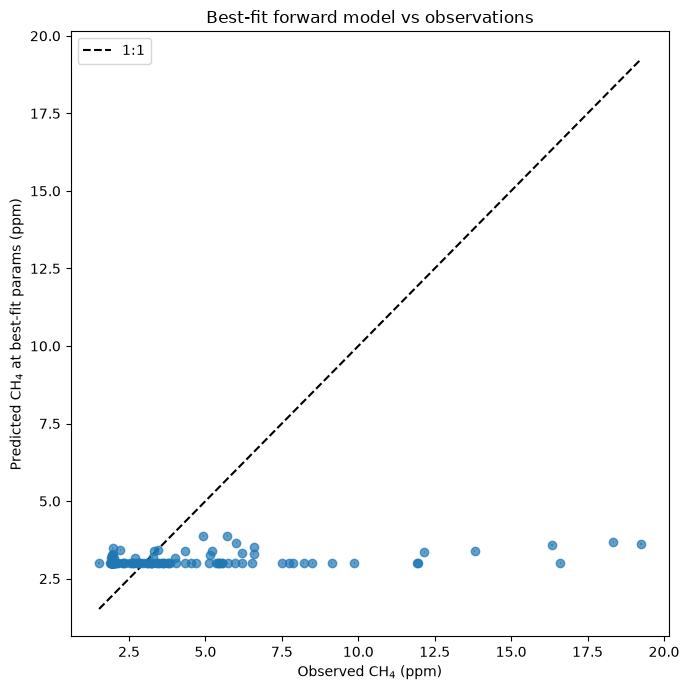

In [ ]:
# Predicted (at best-fit params) vs observed concentrations
import matplotlib.pyplot as plt

best_idx = scores.index[0]
pred = wave0_results.loc[best_idx, obs_cols].to_numpy(dtype=float)

plt.figure(figsize=(7, 7))
plt.errorbar(vals, pred, xerr=sigmas, fmt="o", alpha=0.7)
lims = [min(vals.min(), pred.min()), max(vals.max(), pred.max())]
plt.plot(lims, lims, "k--", label="1:1")
plt.xlabel("Observed CH$_4$ (ppm)")
plt.ylabel("Predicted CH$_4$ at best-fit params (ppm)")
plt.title("Best-fit forward model vs observations")
plt.legend()
plt.tight_layout()
plt.show()

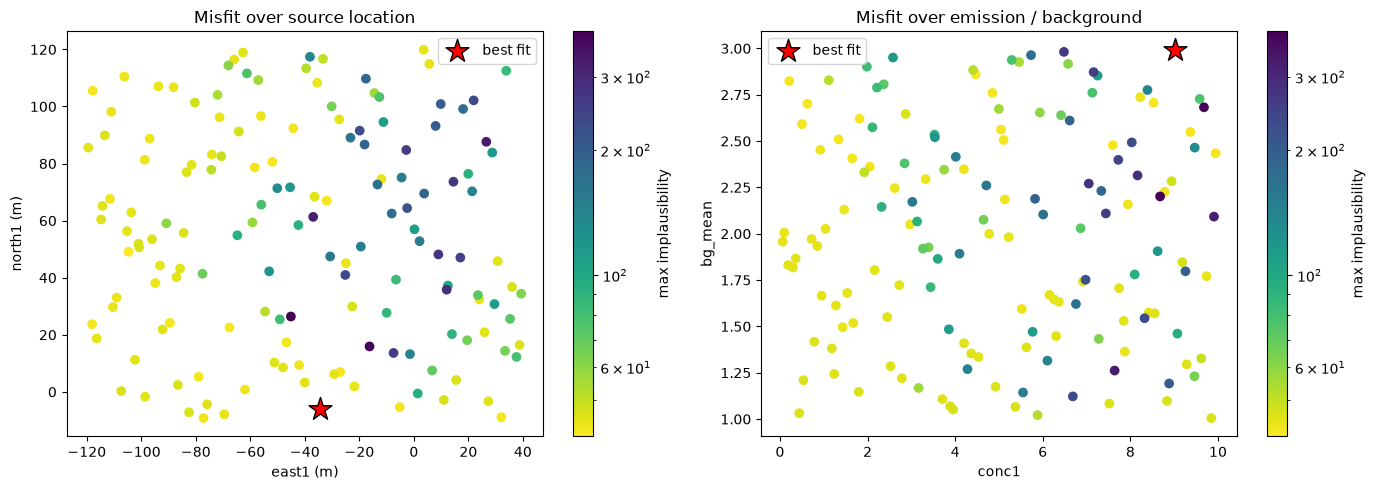

In [ ]:
# Misfit landscape across the sampled space
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc0 = axes[0].scatter(scores["east1"], scores["north1"], c=scores["max_impl"], cmap="viridis_r",norm='log')
axes[0].scatter(best["east1"], best["north1"], marker="*", s=300,
                color="red", edgecolor="k", label="best fit")
axes[0].set_xlabel("east1 (m)")
axes[0].set_ylabel("north1 (m)")
axes[0].set_title("Misfit over source location")
axes[0].legend()
fig.colorbar(sc0, ax=axes[0], label="max implausibility", norm='log')

sc1 = axes[1].scatter(scores["conc1"], scores["bg_mean"], c=scores["max_impl"], cmap="viridis_r", norm='log')
axes[1].scatter(best["conc1"], best["bg_mean"], marker="*", s=300,
                color="red", edgecolor="k", label="best fit")
axes[1].set_xlabel("conc1")
axes[1].set_ylabel("bg_mean")
axes[1].set_title("Misfit over emission / background")
axes[1].legend()
fig.colorbar(sc1, ax=axes[1], label="max implausibility", norm='log')

plt.tight_layout()
plt.show()

In [ ]:
# Export the direct-evaluation results
output_dir = Path("output/")
output_dir.mkdir(parents=True, exist_ok=True)

scores.to_csv(output_dir / "direct_misfit_scores.csv")   # ranked parameter sets + misfit
wave0_results.to_csv(output_dir / "forward_runs.csv")    # full forward-model output
all_obs.to_csv(output_dir / "obs.csv")                   # observations matched against
print(f"Wrote results to {output_dir.resolve()}")

Wrote results to /Users/hamid/durham/hmepy/mirico/output


In [ ]:
# --- Non-implausible region of parameter space ---
# In history matching a point is "non-implausible" if its largest standardised
# residual (max_impl) is below the cutoff (conventionally 3). The bounding box of
# those points is the region of parameter space still consistent with the data.
impl_cutoff = 3.0

non_impl = scores[scores["max_impl"] < impl_cutoff]
print(f"Sampled points                       : {len(scores)}")
print(f"Non-implausible (max_impl < {impl_cutoff})      : {len(non_impl)} "
      f"({100 * len(non_impl) / len(scores):.1f}%)\n")

def describe_region(df, cols, title):
    print(title)
    summary = df[cols].agg(["min", "max", "mean"]).T
    summary["width"] = summary["max"] - summary["min"]
    summary["prior_min"] = [ranges[c][0] for c in cols]
    summary["prior_max"] = [ranges[c][1] for c in cols]
    summary["frac_of_prior"] = summary["width"] / (summary["prior_max"] - summary["prior_min"])
    print(summary.round(4).to_string())
    print()

if len(non_impl) > 0:
    describe_region(non_impl, param_cols,
                    f"Non-implausible region (bounding box over {len(non_impl)} points):")
    print("The [min, max] per parameter is the reduced hyperrectangle that a next")
    print("history-matching wave would resample within.")
else:
    print(f"No sampled point is non-implausible at cutoff {impl_cutoff}: with a single")
    print("coarse pass over wide ranges and very tight observation errors, nothing")
    print("clears the threshold. Showing the best-fitting 5% instead, to indicate")
    print("where the good region lies and how it compares to the prior ranges.\n")
    n_best = max(1, int(0.05 * len(scores)))
    describe_region(scores.head(n_best), param_cols,
                    f"Best {n_best} points by implausibility (approximate good region):")


Sampled points                       : 150
Non-implausible (max_impl < 3.0)      : 0 (0.0%)

No sampled point is non-implausible at cutoff 3.0: with a single
coarse pass over wide ranges and very tight observation errors, nothing
clears the threshold. Showing the best-fitting 5% instead, to indicate
where the good region lies and how it compares to the prior ranges.

Best 7 points by implausibility (approximate good region):
              min      max     mean    width  prior_min  prior_max  frac_of_prior
bg_mean    2.5495   2.9927   2.7132   0.4432          1          3         0.2216
conc1      0.6254   9.3696   5.5534   8.7442          0         10         0.8744
east1   -104.6388  -5.1949 -55.0079  99.4439       -120         40         0.6215
north1    -5.8974  80.6206  33.1812  86.5180        -10        120         0.6655
up1       -0.5716   0.9742   0.1180   1.5459         -1          1         0.7729

